In [37]:
import json
import time
from pathlib import Path
import sys
import duckdb
import numpy as np
import pandas as pd

# --- Percorsi ---
PROJECT_ROOT = Path.cwd().parent                       # .../flow-tokenization
DATA_DIR = PROJECT_ROOT / "data" / "student_dataset"
FLOWS = DATA_DIR / "flows.parquet"
SPLITS = DATA_DIR / "splits.json"

print("flows.parquet esiste:", FLOWS.exists())
print("splits.json esiste:  ", SPLITS.exists())

# --- Riproducibilità ---
SEED = 42
rng = np.random.default_rng(SEED)

# --- Tabella riassuntiva finale: un dict per modello ---
RESULTS = []

# --- Connessione DuckDB ---
con = duckdb.connect()                          # database in memoria
con.execute("SET threads TO 8")                 # core da usare
con.execute("SET memory_limit = '8GB'")         # tetto di RAM per DuckDB
con.execute("SET temp_directory = 'duckdb_tmp'")  # dove scaricare su disco se sfora
con.execute("SET preserve_insertion_order = false")

print("DuckDB", duckdb.__version__)
print(con.execute(f"SELECT COUNT(*) AS n FROM read_parquet('{FLOWS}')").fetchone())
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

flows.parquet esiste: True
splits.json esiste:   True
DuckDB 2.0.0
(67244519,)
Python 3.14.0 | pandas 2.3.3 | numpy 2.5.3


In [38]:
con.execute("SET TimeZone = 'UTC'")

PREPARED = DATA_DIR / "flows_prepared.parquet"
con.execute(f"CREATE OR REPLACE VIEW fp AS SELECT * FROM read_parquet('{PREPARED}')")

con.execute("""
    SELECT split,
           COUNT(*)      AS n,
           MIN(t_start)  AS inizio,
           MAX(t_start)  AS fine
    FROM fp
    GROUP BY split
    ORDER BY MIN(t_start)
""").df()
con.execute("DESCRIBE fp").df()[["column_name", "column_type"]]

,column_name,column_type
0,flow_id,VARCHAR
1,t_start,TIMESTAMP WITH TIME ZONE
2,split,VARCHAR
3,delta_rtt,DOUBLE
4,start_rtt,DOUBLE
5,an_end_rtt,DOUBLE
6,an_endpoints_reversed,BOOLEAN
7,an_durata_s,DOUBLE
8,ip_version,BIGINT
9,experiment,VARCHAR


### Funzione di valutazione

Definisco una funzione unica, `valuta`, che userò per **tutte le baseline**, così le metriche sono calcolate sempre allo stesso modo.

- **Input:** il nome di una vista DuckDB che contiene le righe di validation, con tutte le colonne di `fp` più una colonna `pred` (la previsione del modello).
- **Output:** una tabella con MAE (metrica principale) e RMSE, globali e per sottogruppo.

| Sottogruppo | Definizione | Perché |
|---|---|---|
| globale | tutte le righe | metrica ufficiale |
| FNAL | server o client = `USCMS-FNAL-WC1` | copertura ridotta dopo la rimozione degli `end_rtt = 0` |
| sito mancante | server o client = `MISSING` | ~18% dei flussi senza sito CRIC |
| verso incerto | `verso_incerto = TRUE` | orientamento server/client ambiguo (0,27%) |
| flussi > 1 min | `an_durata_s > 60` | origine del picco a ~5 ms; `an_durata_s` usata **solo per filtrare**, mai come input |

Tutto il calcolo avviene in DuckDB: in Python arrivano solo le metriche, non i 10 M di righe del validation.

In [39]:
SOTTOGRUPPI = {
    "globale":        "TRUE",
    "FNAL":           "server_site = 'USCMS-FNAL-WC1' OR client_site = 'USCMS-FNAL-WC1'",
    "sito mancante":  "server_site = 'MISSING' OR client_site = 'MISSING'",
    "verso incerto":  "verso_incerto",
    "flussi > 1 min": "an_durata_s > 60",
}

def valuta(vista):
    """vista: nome di una vista/tabella DuckDB con le colonne di fp più 'pred'."""
    parti = []
    for nome, cond in SOTTOGRUPPI.items():
        parti.append(f"""
            SELECT '{nome}'                                   AS gruppo,
                   COUNT(*)                                   AS n,
                   AVG(ABS(delta_rtt - pred))                 AS mae,
                   SQRT(AVG((delta_rtt - pred) * (delta_rtt - pred))) AS rmse
            FROM {vista}
            WHERE {cond}
        """)
    return con.execute(" UNION ALL ".join(parti)).df()

### Baseline 0 — Mediana globale

**Idea:** prevedere per ogni flusso lo stesso valore, senza usare nessuna feature. È il **limite inferiore**: qualunque modello deve fare meglio.

**Perché la mediana:** è la costante che minimizza il MAE, la nostra metrica principale. La media minimizzerebbe invece l'RMSE, ma con un target bimodale (picchi a 0 e ~5 ms) e code estreme (fino a +120.000 ms) verrebbe tirata dai valori anomali.

**Passi:**
1. Mediana e media di `delta_rtt` calcolate **solo sul train completo** (46,7 M righe).
2. Vista `pred_b0`: righe di validation con `pred` = mediana del train.
3. Valutazione con `valuta` (globale e sottogruppi).
4. Registrazione in `RESULTS`: modello, MAE, RMSE, numero di parametri (1) e tempo.

**Atteso:** mediana ≈ 4,44 ms (notebook 01); RMSE molto più alto del MAE a causa delle code.

## Baseline 0 – Mediana globale

**Cosa facciamo.** Prevediamo per ogni flow la stessa costante: la mediana di `delta_rtt` calcolata sull'intero train (46,7 M righe). La valutiamo su tutta la validation con MAE e RMSE, globalmente e per i sottogruppi di analisi (FNAL, sito mancante, verso incerto, flow > 1 min).

**Perché la mediana.** Tra tutte le costanti, quella che minimizza la MAE (metrica principale) è la mediana, mentre per l'RMSE sarebbe la media. Calcoliamo anche la media per confronto.

**Perché sul train completo.** DuckDB calcola la mediana su 46,7 M righe senza caricarle in memoria, quindi non serve il campione da ~3 M usato per i modelli. Così la baseline è priva di rumore di campionamento.

**Tempo di training.** Coincide con il tempo di calcolo della mediana; la valutazione è esclusa.

In [40]:
t0 = time.time()
mediana, media = con.execute("""
    SELECT MEDIAN(delta_rtt), AVG(delta_rtt)
    FROM fp
    WHERE split = 'train'
""").fetchone()
print(f"train → mediana: {mediana:.3f} ms | media: {media:.3f} ms")


con.execute(f"""
    CREATE OR REPLACE VIEW pred_b0 AS
    SELECT *, {mediana} AS pred
    FROM fp
    WHERE split = 'val'
""")
ris_b0 = valuta("pred_b0")
durata = time.time() - t0

RESULTS.append({
    "modello": "B0 mediana globale",
    "MAE": ris_b0.loc[0, "mae"],
    "RMSE": ris_b0.loc[0, "rmse"],
    "parametri": 1,
    "tempo_s": round(durata, 1),
})
ris_b0

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train → mediana: 4.398 ms | media: 3.172 ms


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,gruppo,n,mae,rmse
0,globale,10069254,3.297830,47.288974
1,FNAL,215471,1.636414,3.193037
2,sito mancante,2122477,3.539438,16.573741
3,verso incerto,32662,4.569727,8.800912
4,flussi > 1 min,6632723,3.129088,58.018966


### Risultati della baseline 0

| Gruppo | n (val) | MAE (ms) | RMSE (ms) |
|---|---|---|---|
| Globale | 10.069.254 | 3,298 | 47,289 |
| FNAL | 215.471 | 1,636 | 3,193 |
| Sito mancante | 2.122.477 | 3,539 | 16,574 |
| Verso incerto | 32.662 | 4,570 | 8,801 |
| Flow > 1 min | 6.632.723 | 3,129 | 58,019 |

**Osservazioni.**
- **Mediana (4,398 ms) > media (3,172 ms).** La mediana cade nel picco a ~5 ms, che contiene più della metà della massa; la media è spinta verso il basso dal picco a 0 e dal 14 % di valori negativi. Con un target bimodale nessuna costante è vicina a entrambi i picchi: il margine di miglioramento principale sta nel distinguere i due regimi.
- **RMSE / MAE ≈ 14.** L'RMSE è dominato da pochi valori estremi (code pesanti). Un modello può quindi ridurre molto la MAE senza che l'RMSE cambi in modo apprezzabile.
- **Flow > 1 min.** Sono il 66 % della validation, con la MAE più bassa ma l'RMSE più alto: le code estreme si concentrano nei flow lunghi. Il sottogruppo è definito con `an_durata_s`, ammessa solo per l'analisi e mai come input.
- **Sottogruppi.** FNAL è più facile della media; il verso incerto è il caso più difficile ma pesa lo 0,3 %; i flow con sito mancante (21 % della validation) sono leggermente peggiori della media e vanno ricontrollati con la baseline 1.

**Correzione da applicare.** Nella prima esecuzione `tempo_s` misurava la valutazione invece del calcolo della mediana; il cronometro va avviato prima della query della mediana.

## Diagnostica delle code dell'errore

**Cosa facciamo.** Prima di passare ai modelli quantifichiamo quanto l'RMSE dipenda dai valori estremi. Sulla validation calcoliamo:
- i quantili di `delta_rtt` (0,1 %–99,9 %), il minimo e il massimo;
- la quota dell'errore quadratico totale della baseline 0 dovuta allo 0,1 % e all'1 % dei flow peggiori;
- la MAE che si otterrebbe prevedendo la media invece della mediana, come verifica numerica della scelta;
- la mediana della validation, per controllare se il target cambia nel tempo (drift) rispetto al train.

**Perché.** Se una piccola frazione di flow determina la maggior parte dell'RMSE, conviene riportare accanto all'RMSE anche una versione robusta (ad esempio senza lo 0,1 % estremo, o i quantili dell'errore assoluto). Così il confronto tra modelli non dipende da pochi outlier.

**Sintassi SQL nuova.** CTE (`WITH ... AS`) e window function (`ROW_NUMBER() OVER (...)`, `COUNT(*) OVER ()`).

In [41]:
diag = con.execute(f"""
    WITH e AS (
        SELECT
            delta_rtt,
            POWER(delta_rtt - {mediana}, 2) AS se
        FROM fp
        WHERE split = 'val'
    ),
    r AS (
        SELECT
            se,
            ROW_NUMBER() OVER (ORDER BY se DESC) AS rk,
            COUNT(*)     OVER ()                 AS n
        FROM e
    )
    SELECT
        (SELECT quantile_cont(delta_rtt, [0.001, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]) FROM e) AS quantili,
        (SELECT MIN(delta_rtt) FROM e) AS minimo,
        (SELECT MAX(delta_rtt) FROM e) AS massimo,
        (SELECT AVG(ABS(delta_rtt - {media}))   FROM e) AS mae_con_media,
        (SELECT MEDIAN(delta_rtt)               FROM e) AS mediana_val,
        SUM(CASE WHEN rk <= n * 0.001 THEN se ELSE 0 END) / SUM(se) AS quota_se_top01,
        SUM(CASE WHEN rk <= n * 0.01  THEN se ELSE 0 END) / SUM(se) AS quota_se_top1
    FROM r
""").df()
diag.T

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,0
quantili,"[-63.148988, -4.536999999999999, -0.2279999999..."
minimo,-2108.184
massimo,32518.112
mae_con_media,3.387719
mediana_val,4.442
quota_se_top01,0.988416
quota_se_top1,0.9936


### Metriche robuste: soglie del set "tipico"

**Perché.** Lo 0,1 % dei flow (~10.000) produce il 98,8 % dell'errore quadratico della baseline 0: l'RMSE sull'intera validation è deciso da pochi valori estremi. Accanto all'RMSE completo riportiamo quindi un **RMSE robusto (†)**.

**Definizione.** Un flow è *tipico* se il suo `delta_rtt` sta tra il quantile 0,05 % e il 99,95 % del **train**. L'insieme dipende solo dal valore vero, non dalle previsioni, ed è quindi **lo stesso per tutti i modelli**. Le soglie si calcolano sul train per evitare leakage.

**Regola di presentazione.** Ogni tabella riporta sempre entrambi gli RMSE; quello robusto è marcato con † e accompagnato dalla nota sulla sua definizione.

**Cosa fa la cella.** Calcola le due soglie sul train (`LO`, `HI`), prepara la nota `NOTA_ROBUSTO` da stampare sotto ogni tabella e conta quanti flow di train e validation restano nel set tipico. Atteso: ~99,9 % sul train per costruzione, un valore simile sulla validation.

In [42]:
Q_LO, Q_HI = 0.0005, 0.9995

LO, HI = con.execute(f"""
    SELECT quantile_cont(delta_rtt, [{Q_LO}, {Q_HI}])
    FROM fp
    WHERE split = 'train'
""").fetchone()[0]

NOTA_ROBUSTO = (f"† RMSE robusto: calcolato solo sui flow con delta_rtt in [{LO:.2f}, {HI:.2f}] ms, "
                f"cioè tra i quantili {Q_LO:.2%} e {Q_HI:.2%} del train (insieme fisso, uguale per tutti i modelli).")

print(f"Soglie dal train: LO = {LO:.3f} ms | HI = {HI:.3f} ms")

con.execute(f"""
    SELECT split,
           COUNT(*)                                                    AS n,
           COUNT(*) FILTER (WHERE delta_rtt BETWEEN {LO} AND {HI})     AS n_tipici,
           100 * AVG(CASE WHEN delta_rtt BETWEEN {LO} AND {HI} THEN 1 ELSE 0 END) AS pct_tipici
    FROM fp
    WHERE split IN ('train', 'val')
    GROUP BY split
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Soglie dal train: LO = -184.233 ms | HI = 58.823 ms


,split,n,n_tipici,pct_tipici
0,val,10069254,10061030,99.918326
1,train,46730686,46683954,99.899997


### Risultati: soglie del set tipico

| Split | Flow | Tipici | % tipici |
|---|---|---|---|
| train | 46.730.686 | 46.683.954 | 99,900 % |
| validation | 10.069.254 | 10.061.030 | 99,918 % |

- **Soglie dal train:** LO = −184,23 ms, HI = +58,82 ms. Sono asimmetriche perché seguono la forma della distribuzione: a questi quantili la coda negativa è più lunga, mentre gli estremi assoluti sono positivi (fino a +32.518 ms in validation). Usare quantili evita di fissare a occhio una soglia simmetrica.
- **Train:** 99,900 % tipici, cioè esattamente lo 0,1 % escluso per costruzione.
- **Validation:** 99,918 % tipici, 8.224 flow esclusi (0,082 %). La validation ha circa il 18 % di valori estremi in meno del train. La differenza non è dovuta al caso: con la frequenza del train ci aspetteremmo ~10.069 ± 100 esclusi.

**Collegamento con l'esplorazione (ipotesi, non verificata).** La settimana di dati non è stazionaria:
- le misure mancanti (`end_rtt = 0`, concentrate verso USCMS-FNAL-WC1) calano da 0,72 % (train) a 0,17 % (validation) e 0,003 % (test);
- il traffico da reti senza sito CRIC cala da 16,8 % a 11,5 %, e con esso la quota di siti sorgente mancanti (19,6 % → 17,9 % → 13,4 %).

Anche la minore frequenza di valori estremi in validation va nella stessa direzione: con il passare dei giorni cambiano sia la qualità delle misure sia la composizione del traffico. Le RTT nulle sono già state rimosse, quindi non sono loro gli estremi residui: il legame causale resta da verificare, ad esempio guardando su quali coppie di siti e con quale durata si concentrano i flow esclusi.

**Conseguenza per la valutazione.** Il set tipico esclude più dati nel train che nella validation; poiché è definito sul valore vero con soglie fisse, resta comunque lo stesso per tutti i modelli e il confronto tra modelli non ne è influenzato.

### Funzione di valutazione

Una funzione unica, `valuta`, calcola le metriche di **tutte le baseline**, sempre allo stesso modo e interamente in DuckDB (in Python arrivano solo le metriche).

- **Input:** il nome di una vista con le righe di validation, le colonne di `fp` e una colonna `pred`.
- **Output:** una riga per sottogruppo, con:

| Metrica | Definizione | Note |
|---|---|---|
| MAE | media di \|errore\| | metrica principale |
| RMSE | radice della media di errore² su tutte le righe | dominato dai flow estremi |
| RMSE robusto † | RMSE sui soli flow tipici (`delta_rtt` in [LO, HI], quantili 0,05–99,95 % del train) | insieme fisso, uguale per tutti i modelli |
| P90, P99 \|err\| | 90° e 99° percentile dell'errore assoluto | "nel 90 % dei flow sbaglio meno di…" |

| Sottogruppo | Definizione | Perché |
|---|---|---|
| globale | tutte le righe | metrica ufficiale |
| FNAL | server o client = `USCMS-FNAL-WC1` | copertura ridotta dopo la rimozione degli `end_rtt = 0` |
| sito mancante | server o client = `MISSING` | ~18 % dei flow senza sito CRIC |
| verso incerto | `verso_incerto = TRUE` | orientamento ambiguo (0,27 %) |
| flow > 1 min | `an_durata_s > 60` | origine del picco a ~5 ms; durata usata **solo per filtrare** |

`mostra` stampa la tabella con i nomi delle metriche e, sotto, la nota sull'RMSE robusto. Le righe sono ordinate esplicitamente, perché DuckDB (con `preserve_insertion_order = false`) non garantisce l'ordine di un `UNION ALL`.

In [43]:
SOTTOGRUPPI = {
    "globale":       "TRUE",
    "FNAL":          "server_site = 'USCMS-FNAL-WC1' OR client_site = 'USCMS-FNAL-WC1'",
    "sito mancante": "server_site = 'MISSING' OR client_site = 'MISSING'",
    "verso incerto": "verso_incerto",
    "flow > 1 min":  "an_durata_s > 60",
}

def valuta(vista):
    """vista: nome di una vista DuckDB con le colonne di fp più 'pred' (solo righe di validation)."""
    parti = []
    for ordine, (nome, cond) in enumerate(SOTTOGRUPPI.items()):
        parti.append(f"""
            SELECT {ordine}  AS ordine,
                   '{nome}'  AS gruppo,
                   COUNT(*)  AS n,
                   AVG(ABS(delta_rtt - pred))                         AS mae,
                   SQRT(AVG(POWER(delta_rtt - pred, 2)))              AS rmse,
                   SQRT(AVG(POWER(delta_rtt - pred, 2))
                        FILTER (WHERE delta_rtt BETWEEN {LO} AND {HI})) AS rmse_robusto,
                   quantile_cont(ABS(delta_rtt - pred), 0.90)         AS p90_abs,
                   quantile_cont(ABS(delta_rtt - pred), 0.99)         AS p99_abs
            FROM {vista}
            WHERE {cond}
        """)
    query = "SELECT * FROM (" + " UNION ALL ".join(parti) + ") ORDER BY ordine"
    return con.execute(query).df().drop(columns="ordine")

NOMI_METRICHE = {
    "mae": "MAE", "rmse": "RMSE", "rmse_robusto": "RMSE robusto †",
    "p90_abs": "P90 |err|", "p99_abs": "P99 |err|",
}

def mostra(ris):
    """Stampa la tabella delle metriche (ms) con la nota sull'RMSE robusto."""
    display(ris.rename(columns=NOMI_METRICHE).round(3))
    print(NOTA_ROBUSTO)

**Aggiornamento.** La baseline 0 viene rieseguita con la nuova `valuta` (RMSE robusto †, P90, P99) e con il tempo di training misurato correttamente: solo il calcolo della mediana sul train, esclusa la valutazione. Se la cella viene rieseguita, la riga precedente di B0 in `RESULTS` viene sostituita, non duplicata.

In [44]:
# --- "Training": mediana (e media, per confronto) sul train completo ---
t0 = time.time()
mediana, media = con.execute("""
    SELECT MEDIAN(delta_rtt), AVG(delta_rtt)
    FROM fp
    WHERE split = 'train'
""").fetchone()
t_train = time.time() - t0
print(f"train → mediana: {mediana:.3f} ms | media: {media:.3f} ms | tempo: {t_train:.1f} s")

# --- Previsione e valutazione sulla validation ---
con.execute(f"""
    CREATE OR REPLACE VIEW pred_b0 AS
    SELECT *, {mediana} AS pred
    FROM fp
    WHERE split = 'val'
""")
ris_b0 = valuta("pred_b0")
glob = ris_b0.set_index("gruppo").loc["globale"]

# --- Registrazione (sostituisce un'eventuale riga B0 precedente) ---
RESULTS = [r for r in RESULTS if r["modello"] != "B0 mediana globale"]
RESULTS.append({
    "modello":        "B0 mediana globale",
    "MAE":            glob["mae"],
    "RMSE":           glob["rmse"],
    "RMSE robusto †": glob["rmse_robusto"],
    "P90 |err|":      glob["p90_abs"],
    "P99 |err|":      glob["p99_abs"],
    "parametri":      1,
    "tempo_train_s":  round(t_train, 1),
})

mostra(ris_b0)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

train → mediana: 4.398 ms | media: 3.172 ms | tempo: 2.8 s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,gruppo,n,MAE,RMSE,RMSE robusto †,P90 |err|,P99 |err|
0,globale,10069254,3.298,47.289,5.812,4.510,23.552
1,FNAL,215471,1.636,3.193,2.666,4.381,6.279
2,sito mancante,2122477,3.539,16.574,6.885,4.847,25.834
3,verso incerto,32662,4.570,8.801,4.790,4.423,5.541
4,flow > 1 min,6632723,3.129,58.019,6.453,4.643,27.535


† RMSE robusto: calcolato solo sui flow con delta_rtt in [-184.23, 58.82] ms, cioè tra i quantili 0.05% e 99.95% del train (insieme fisso, uguale per tutti i modelli).


### Ri-verifica della scelta su `application` (solo validation)

**Contesto.** Nella preparazione abbiamo deciso di **non normalizzare** `application`: ad esempio `python3.12` e `python3.13` restano valori distinti, non diventano un unico `python`. La giustificazione si basava sui valori nuovi osservati nel **test**, che non va usato per prendere decisioni.

**Cosa facciamo.** Ripetiamo il controllo sulla sola validation: elenchiamo i valori di `application` presenti in validation ma **mai visti nel train** (diventerebbero `UNK`) e misuriamo quante righe coprono.

**Come si legge.**
- Se i valori nuovi sono soprattutto **job di analisi** (nomi di script, hash), la normalizzazione non servirebbe: nessuna regola li riconduce a un valore noto, quindi la scelta resta valida.
- Se fossero soprattutto **nuove versioni di programmi noti** (es. `python3.14`), una normalizzazione ridurrebbe gli `UNK` e andrebbe riconsiderata.
- In ogni caso, se le righe coinvolte sono poche, l'effetto pratico è trascurabile.

In [45]:
n_val = con.execute("SELECT COUNT(*) FROM fp WHERE split = 'val'").fetchone()[0]

nuove_app = con.execute(f"""
    WITH app_train AS (
        SELECT DISTINCT application
        FROM fp
        WHERE split = 'train'
    ),
    app_val AS (
        SELECT application, COUNT(*) AS n
        FROM fp
        WHERE split = 'val'
        GROUP BY application
    )
    SELECT application,
           n,
           100.0 * n / {n_val}                  AS pct_val,
           application ILIKE '%python%'          AS sembra_python
    FROM app_val
    ANTI JOIN app_train USING (application)
    ORDER BY n DESC
""").df()

print(f"Valori di application nuovi in validation: {len(nuove_app)}")
print(f"Righe coinvolte: {nuove_app['n'].sum():,} ({nuove_app['pct_val'].sum():.3f} % della validation)")
print(f"Di cui 'python*': {nuove_app['sembra_python'].sum()} valori, "
      f"{nuove_app.loc[nuove_app['sembra_python'], 'n'].sum():,} righe")
nuove_app.head(25)

Valori di application nuovi in validation: 15
Righe coinvolte: 3,694 (0.037 % della validation)
Di cui 'python*': 0 valori, 0 righe


,application,n,pct_val,sembra_python
0,vbfhmm_config_run3_WCR_v5_24_nohehf_data_2024,1490,0.014798,False
1,vhmm_config_data_2024,729,0.007240,False
2,vbfhmm_config_run3_WCR_v5_24_nohehf_mc_2024,417,0.004141,False
3,config_run3_noiso_validation_data_2018,260,0.002582,False
4,main.exe,189,0.001877,False
5,vhmm_config_vhmm_2024,173,0.001718,False
6,ee,171,0.001698,False
7,o2-analysis-dq-table-maker-mc-with-assoc,135,0.001341,False
8,config_run3_noiso_vsjet0_validation_data_2018,85,0.000844,False
9,o2-analysis-lf-double-omega-builder,24,0.000238,False


**Esito.** In validation compaiono 15 valori di `application` assenti dal train, per 3.694 righe (0,037 %). Nessuno è una versione di Python: sono tutti job di analisi (configurazioni di analisi dell'Higgs come `vbfhmm_config_…` e `vhmm_config_…`, task O2 di ALICE come `o2-analysis-…`, eseguibili generici come `main.exe`). Nessuna normalizzazione li ricondurrebbe a valori noti, quindi la scelta di **non normalizzare** `application` è confermata usando solo train e validation; i valori nuovi diventano `UNK`. Il test non è stato usato per questa decisione.

## Baseline 1 – Mediana per tratta, con fallback gerarchico

**Idea.** Invece di una sola mediana, ne calcoliamo una per ogni tratta della rete (coppia di estremi) sul train completo, e prevediamo per ogni flow della validation la mediana della sua tratta. È una tabella di consultazione: nessun parametro ottimizzato. Misura quanta parte di `delta_rtt` è spiegata dal solo "dove".

**Varianti (6).** Due identificatori × tre orientamenti:

| | non orientata {A, B} | server → client | src → dst |
|---|---|---|---|
| siti CRIC (`MISSING` incluso) | B1 site non_orientata | B1 site server_client | B1 site src_dst |
| prefissi L2 (/24, /48) | B1 L2 non_orientata | B1 L2 server_client | B1 L2 src_dst |

- **Non orientata:** (A, B) e (B, A) sono lo stesso gruppo (chiave = `LEAST`, `GREATEST` dei due nomi).
- **Server → client:** conta quale estremo offre il servizio.
- **Src → dst:** conta il verso con cui il Firefly ha registrato il flow, che dipende dal protocollo.
- Il verso dei byte non è osservato (il campo `usage` non è nel dataset): l'"ordine" riguarda i ruoli o la registrazione, non chi invia i dati.

**Fallback, uguale per tutte le varianti:** coppia (siti o prefissi) → coppia di ASN (stesso orientamento) → mediana globale. Un gruppo si usa solo se ha almeno **N = 1.000** righe di train (stessa soglia dei vocabolari: compromesso tra specificità e rumore della mediana).

**Domande.**
- non orientata ≈ orientate → la direzione non porta informazione;
- prefissi meglio dei siti → i prefissi recuperano informazione dove il sito è `MISSING`.

**Registriamo** per ogni variante: metriche (globali e per sottogruppo), quota di flow della validation decisi a ciascun livello del fallback, numero di mediane memorizzate ("parametri") e tempo di calcolo delle mediane.

In [46]:
# Espressioni SQL delle due chiavi di una coppia, per orientamento.
# {p} = prefisso di tabella ("f." oppure ""), {x} = identificatore ("site", "L2", "asn")
ORIENTAMENTI = {
    "non_orientata": ("LEAST({p}server_{x}, {p}client_{x})",
                      "GREATEST({p}server_{x}, {p}client_{x})"),
    "server_client": ("{p}server_{x}", "{p}client_{x}"),
    "src_dst":       ("{p}src_{x}",    "{p}dst_{x}"),
}

def chiavi(orient, x, p=""):
    """Restituisce le due espressioni SQL della coppia per un orientamento e un identificatore."""
    k1, k2 = ORIENTAMENTI[orient]
    return k1.format(p=p, x=x), k2.format(p=p, x=x)

def baseline1(ident, orient, N=1000):
    """ident: 'site' o 'L2'; orient: chiave di ORIENTAMENTI; N: righe minime di train per gruppo."""
    t0 = time.time()
    # Livello 1: coppia di siti o prefissi; livello 2: coppia di ASN (stesso orientamento)
    for livello, x in [(1, ident), (2, "asn")]:
        k1, k2 = chiavi(orient, x)
        con.execute(f"""
            CREATE OR REPLACE TEMP TABLE med_l{livello} AS
            SELECT {k1} AS k1, {k2} AS k2,
                   MEDIAN(delta_rtt) AS med,
                   COUNT(*)          AS n
            FROM fp
            WHERE split = 'train'
            GROUP BY ALL
            HAVING COUNT(*) >= {N}
        """)
    t_train = time.time() - t0

    # Previsione sulla validation: il primo livello disponibile vince
    a1, b1 = chiavi(orient, ident, p="f.")
    a2, b2 = chiavi(orient, "asn", p="f.")
    con.execute(f"""
        CREATE OR REPLACE VIEW pred_b1 AS
        SELECT f.*,
               COALESCE(m1.med, m2.med, {mediana}) AS pred,
               CASE WHEN m1.med IS NOT NULL THEN '1 coppia {ident}'
                    WHEN m2.med IS NOT NULL THEN '2 coppia ASN'
                    ELSE                         '3 globale' END AS livello
        FROM fp AS f
        LEFT JOIN med_l1 AS m1 ON {a1} = m1.k1 AND {b1} = m1.k2
        LEFT JOIN med_l2 AS m2 ON {a2} = m2.k1 AND {b2} = m2.k2
        WHERE f.split = 'val'
    """)

    ris = valuta("pred_b1")
    livelli = con.execute("""
        SELECT livello,
               COUNT(*)                                    AS n,
               100.0 * COUNT(*) / SUM(COUNT(*)) OVER ()    AS pct,
               AVG(ABS(delta_rtt - pred))                  AS mae
        FROM pred_b1
        GROUP BY livello
        ORDER BY livello
    """).df()
    n_param = sum(con.execute(f"SELECT COUNT(*) FROM med_l{l}").fetchone()[0] for l in (1, 2)) + 1
    return ris, livelli, n_param, t_train

### Esecuzione delle sei varianti

Per ogni combinazione di identificatore (siti, prefissi L2) e orientamento (non orientata, server → client, src → dst) calcoliamo le mediane sul train, valutiamo sulla validation e registriamo i risultati in `RESULTS`. Le tabelle di dettaglio (sottogruppi e livelli del fallback) restano in `DETTAGLI_B1`; sotto mostriamo il confronto globale.

In [47]:
DETTAGLI_B1 = {}

for ident in ["site", "L2"]:
    for orient in ORIENTAMENTI:
        nome = f"B1 {ident} {orient}"
        ris, livelli, n_param, t_train = baseline1(ident, orient)
        DETTAGLI_B1[nome] = {"ris": ris, "livelli": livelli}

        glob = ris.set_index("gruppo").loc["globale"]
        RESULTS = [r for r in RESULTS if r["modello"] != nome]
        RESULTS.append({
            "modello":        nome,
            "MAE":            glob["mae"],
            "RMSE":           glob["rmse"],
            "RMSE robusto †": glob["rmse_robusto"],
            "P90 |err|":      glob["p90_abs"],
            "P99 |err|":      glob["p99_abs"],
            "parametri":      n_param,
            "tempo_train_s":  round(t_train, 1),
        })
        print(f"{nome:28s} MAE = {glob['mae']:.3f} | livello 1: {livelli['pct'].iloc[0]:.1f} % | {t_train:.1f} s")

display(pd.DataFrame(RESULTS).round(3))
print(NOTA_ROBUSTO)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

B1 site non_orientata        MAE = 2.463 | livello 1: 99.8 % | 4.2 s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

B1 site server_client        MAE = 2.270 | livello 1: 99.7 % | 3.7 s


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

B1 site src_dst              MAE = 2.401 | livello 1: 99.7 % | 3.3 s


... (6 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

B1 L2 src_dst                MAE = 2.310 | livello 1: 97.8 % | 4.1 s


,modello,MAE,RMSE,RMSE robusto †,P90 |err|,P99 |err|,parametri,tempo_train_s
0,B0 mediana globale,3.298,47.289,5.812,4.510,23.552,1,2.8
1,B1 site non_orientata,2.463,47.252,5.515,4.977,23.283,816,4.2
2,B1 site server_client,2.270,47.241,5.419,4.909,23.188,1077,3.7
3,B1 site src_dst,2.401,47.248,5.480,4.953,23.276,1029,3.3
4,B1 L2 non_orientata,2.338,47.241,5.440,4.884,23.240,1920,6.2
5,B1 L2 server_client,2.209,47.233,5.377,4.861,23.068,2166,3.9
6,B1 L2 src_dst,2.310,47.239,5.423,4.868,23.236,2140,4.1


† RMSE robusto: calcolato solo sui flow con delta_rtt in [-184.23, 58.82] ms, cioè tra i quantili 0.05% e 99.95% del train (insieme fisso, uguale per tutti i modelli).


### Risultati della baseline 1

| Variante | MAE | RMSE | RMSE robusto † | P90 \|err\| | P99 \|err\| | mediane | tempo (s) |
|---|---|---|---|---|---|---|---|
| B0 mediana globale | 3,298 | 47,289 | 5,812 | 4,510 | 23,552 | 1 | 1,4 |
| B1 siti, non orientata | 2,463 | 47,252 | 5,515 | 4,977 | 23,283 | 816 | 1,9 |
| B1 siti, server → client | 2,270 | 47,241 | 5,419 | 4,909 | 23,188 | 1.077 | 1,3 |
| B1 siti, src → dst | 2,401 | 47,248 | 5,480 | 4,953 | 23,276 | 1.029 | 1,2 |
| B1 L2, non orientata | 2,338 | 47,241 | 5,440 | 4,884 | 23,240 | 1.920 | 2,3 |
| **B1 L2, server → client** | **2,209** | 47,233 | 5,377 | 4,861 | 23,068 | 2.166 | 1,3 |
| B1 L2, src → dst | 2,310 | 47,239 | 5,423 | 4,868 | 23,236 | 2.140 | 1,4 |

Valori in ms, validation. † RMSE sui soli flow con `delta_rtt` in [−184,23, 58,82] ms (quantili 0,05–99,95 % del train; insieme fisso).

- **La tratta spiega parte dell'errore:** MAE da 3,30 a 2,21 ms (−33 %) con la variante migliore (prefissi L2, server → client).
- **Conta il ruolo, non il verso di registrazione:** server → client è la migliore con entrambi gli identificatori; src → dst sta tra questa e la non orientata, perché coincide con il ruolo solo nei flow registrati client → server (XRootD).
- **Prefissi L2 migliori dei siti** in tutti gli orientamenti (ipotesi: recuperano informazione dove il sito è `MISSING`; da verificare sui sottogruppi).
- **RMSE invariato, RMSE robusto † −7 %:** la tratta non spiega i valori estremi.
- **P90 in aumento (4,51 → 4,86):** dentro ogni tratta restano i due regimi (flow brevi a 0, lunghi a ~5 ms); quando la mediana di una tratta cade nel picco a 0, i flow lunghi sbagliano di ~5 ms. La MAE media migliora, ma la tratta da sola non distingue i due regimi.
- **Fallback poco usato:** il livello 1 decide il 99,7 % dei flow con i siti e il 98 % con i prefissi.

### Dettaglio per sottogruppo: siti contro prefissi (server → client)

Confrontiamo B0 e le due varianti server → client sui sottogruppi, per verificare se il vantaggio dei prefissi si concentra sui flow con sito mancante, e guardiamo i livelli del fallback della variante migliore.

In [48]:
scelte = {
    "B0":         ris_b0,
    "B1 siti":    DETTAGLI_B1["B1 site server_client"]["ris"],
    "B1 L2":      DETTAGLI_B1["B1 L2 server_client"]["ris"],
}
colonne = ["mae", "rmse_robusto", "p90_abs"]

confronto = pd.concat(
    {nome: df.set_index("gruppo")[colonne] for nome, df in scelte.items()},
    axis=1,
)
confronto = confronto.rename(columns=NOMI_METRICHE, level=1).round(3)
display(confronto)
print(NOTA_ROBUSTO)

display(DETTAGLI_B1["B1 L2 server_client"]["livelli"].round(3))

B0                          B1 siti                 \
                 MAE RMSE robusto † P90 |err|     MAE RMSE robusto †   
gruppo                                                                 
globale        3.298          5.812     4.510   2.270          5.419   
FNAL           1.636          2.666     4.381   3.419          4.052   
sito mancante  3.539          6.885     4.847   2.611          6.544   
verso incerto  4.570          4.790     4.423   0.886          2.529   
flow > 1 min   3.129          6.453     4.643   2.761          6.334   

                         B1 L2                           
              P90 |err|    MAE RMSE robusto † P90 |err|  
gruppo                                                   
globale           4.909  2.209          5.377     4.861  
FNAL              4.812  3.396          4.031     4.806  
sito mancante     5.035  2.380          6.419     4.885  
verso incerto     4.838  0.451          2.086     0.286  
flow > 1 min      5.103  2.707          6.293     5.061

† RMSE robusto: calcolato solo sui flow con delta_rtt in [-184.23, 58.82] ms, cioè tra i quantili 0.05% e 99.95% del train (insieme fisso, uguale per tutti i modelli).


,livello,n,pct,mae
0,1 coppia L2,9847582,97.799,2.176
1,2 coppia ASN,206076,2.047,3.629
2,3 globale,15596,0.155,4.535


### Dettaglio per sottogruppo (server → client)

| Gruppo | MAE B0 | MAE B1 siti | MAE B1 L2 | P90 B0 | P90 B1 L2 |
|---|---|---|---|---|---|
| globale | 3,298 | 2,270 | 2,209 | 4,510 | 4,861 |
| FNAL | 1,636 | 3,419 | 3,396 | 4,381 | 4,806 |
| sito mancante | 3,539 | 2,611 | 2,380 | 4,847 | 4,885 |
| verso incerto | 4,570 | 0,886 | 0,451 | 4,423 | 0,286 |
| flow > 1 min | 3,129 | 2,761 | 2,707 | 4,643 | 5,061 |

- **FNAL peggiora (1,64 → 3,40).** Ipotesi: nel train, sulle coppie verso USCMS-FNAL-WC1, l'89–100 % dei flow aveva `end_rtt = 0` ed è stato rimosso; le mediane di quelle tratte sono stimate su pochi flow non rappresentativi. In validation il problema di telemetria è quasi assente (0,17 %) e le mediane del train non valgono più: un caso di drift legato alla qualità delle misure. Verifica nella cella seguente.
- **Sito mancante:** i prefissi migliorano più dei siti (2,38 contro 2,61): recuperano informazione dove il sito CRIC manca.
- **Verso incerto:** MAE da 4,57 a 0,45; flow concentrati su tratte con `delta_rtt` vicino a 0.
- **Fallback:** livello coppia L2 per il 97,8 % dei flow (MAE 2,18), coppia ASN 2,0 % (3,63), globale 0,16 % (4,54).

#### Perché la MAE scende ma il P90 sale

- **MAE** = media degli errori assoluti: misura quanto si sbaglia in totale.
- **P90** = valore sotto cui cade il 90 % degli errori assoluti (90° percentile): "nel 90 % dei flow sbaglio di meno di X ms". Ignora il 10 % peggiore.

Le due metriche possono muoversi in direzioni opposte. Esempio con 10 flow:

| | Errori | MAE | P90 |
|---|---|---|---|
| B0 (sempre 4,4) | 5 flow con errore 0,6 · 5 flow con errore 4,4 | 2,5 | 4,4 |
| B1 (mediana per tratta) | 6 flow con errore 0,1 · 4 flow con errore 5,0 | 2,06 | 5,0 |

Con la B1:
- **molti flow passano a un errore quasi nullo (0,1)**, e la MAE scende;
- **i flow che restano sbagliati sbagliano un po' di più (5,0 invece di 4,4)**, e il P90 sale.

Nei nostri dati: dentro ogni tratta restano flow brevi (picco a ~0 ms) e lunghi (picco a ~5 ms). Quelli dalla parte opposta della mediana della propria tratta sbagliano di circa 5 ms, la distanza piena tra i due picchi, mentre con la mediana globale (4,4 ms) l'errore "tipico" massimo era 4,4. Il modello è migliore in media, ma i suoi errori residui sono un po' più grandi: la tratta da sola non distingue i due regimi.

### Verifica: perché la B1 peggiora su FNAL

Per le tratte con USCMS-FNAL-WC1 (server o client) confrontiamo, tra train e validation: numero di flow, mediana di `delta_rtt` e quota di flow lunghi (> 1 min). Se le mediane del train sono molto diverse da quelle della validation, e il train ha pochi flow per tratta, l'ipotesi del drift dovuto alla pulizia degli `end_rtt = 0` è confermata. La durata è usata solo per descrivere, mai come input.

In [49]:
con.execute("""
    SELECT server_site, client_site, split,
           COUNT(*)                                                AS n,
           MEDIAN(delta_rtt)                                       AS mediana,
           100 * AVG(CASE WHEN an_durata_s > 60 THEN 1 ELSE 0 END) AS pct_lunghi
    FROM fp
    WHERE split IN ('train', 'val')
      AND (server_site = 'USCMS-FNAL-WC1' OR client_site = 'USCMS-FNAL-WC1')
    GROUP BY server_site, client_site, split
    QUALIFY SUM(COUNT(*)) OVER (PARTITION BY server_site, client_site) >= 5000
    ORDER BY server_site, client_site, split DESC
""").df().round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,server_site,client_site,split,n,mediana,pct_lunghi
0,CERN-PROD,USCMS-FNAL-WC1,val,14635,4.399,22.152
1,CERN-PROD,USCMS-FNAL-WC1,train,188397,0.218,10.999
2,GLOW,USCMS-FNAL-WC1,val,116621,4.818,75.709
3,GLOW,USCMS-FNAL-WC1,train,297405,0.722,60.858
4,MISSING,USCMS-FNAL-WC1,val,13947,5.018,85.495
5,MISSING,USCMS-FNAL-WC1,train,42068,1.090,63.019
6,MIT_CMS,USCMS-FNAL-WC1,val,23010,4.996,84.389
7,MIT_CMS,USCMS-FNAL-WC1,train,96216,0.366,37.315
8,Nebraska,USCMS-FNAL-WC1,val,6830,4.168,49.400
9,Nebraska,USCMS-FNAL-WC1,train,79719,0.491,43.064


### Verifica FNAL: risultati

Sulle tratte con USCMS-FNAL-WC1 come client, la mediana di `delta_rtt` passa da ~0,2–1,3 ms nel train a ~4,2–5,0 ms in validation, e la quota di flow lunghi (> 1 min) cresce molto (es. MIT_CMS → FNAL: 37 % → 84 %; UCSDT2 → FNAL: 73 % → 95 %). Le tratte con FNAL come server (FNAL → CERN-PROD, GRIF, UFlorida-HPC) hanno invece mediane stabili (~0,01–0,02 ms in entrambi gli split).

**Interpretazione.** Il problema non è il numero di flow nel train (es. 188.397 per CERN-PROD → FNAL), ma *quali* flow sono rimasti dopo la pulizia. Ipotesi: il guasto di telemetria `end_rtt = 0`, concentrato sui flow verso FNAL e quasi risolto in validation, colpiva soprattutto i flow lunghi; rimuovendoli, nel train sono rimasti soprattutto flow brevi (mediana ~0). È un caso di dato **mancante non a caso** (*missing not at random*), che produce un **bias di selezione**: le mediane del train non rappresentano più la validation. Spiega il peggioramento della B1 su FNAL (MAE 1,64 → 3,40), mentre la B0 prevedeva per caso un valore vicino a quello corretto.

**Cautela.** Parte dell'aumento dei flow lunghi potrebbe essere un cambiamento reale del traffico. La cella seguente verifica l'ipotesi sul solo train: se i flow verso FNAL con `end_rtt = 0` sono molto più spesso lunghi di quelli con `end_rtt > 0`, il meccanismo è confermato.

### Verifica: i flow rimossi verso FNAL erano più lunghi?

Sul file grezzo, solo nel periodo di train, confrontiamo i flow con destinazione USCMS-FNAL-WC1 con `end_rtt = 0` (rimossi dalla pulizia) e con `end_rtt > 0` (rimasti): numero, quota di flow lunghi (> 1 min) e durata mediana, separatamente per sito sorgente. La durata è usata solo per l'analisi. Validation e test non vengono letti.

In [50]:
with open(SPLITS) as f:
    TRAIN_END = json.load(f)["train_end_inclusive"]

con.execute(f"""
    WITH grezzo_train AS (
        SELECT "meta.cric.src.name" AS src,
               end_rtt = 0           AS end_mancante,
               epoch(CAST(flow_end   AS TIMESTAMPTZ))
             - epoch(CAST(flow_start AS TIMESTAMPTZ)) AS durata_s
        FROM read_parquet('{FLOWS}')
        WHERE CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{TRAIN_END}'
          AND "meta.cric.dst.name" = 'USCMS-FNAL-WC1'
          AND start_rtt > 0
    )
    SELECT src,
           end_mancante,
           COUNT(*)                                             AS n,
           100 * AVG(CASE WHEN durata_s > 60 THEN 1 ELSE 0 END) AS pct_lunghi,
           MEDIAN(durata_s)                                     AS durata_mediana_s
    FROM grezzo_train
    GROUP BY src, end_mancante
    HAVING COUNT(*) >= 1000
    ORDER BY src, end_mancante
""").df().round(2)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,src,end_mancante,n,pct_lunghi,durata_mediana_s
0,GLOW,False,21557,12.55,0.22
1,GLOW,True,52744,13.72,11.94
2,MIT_CMS,False,11702,17.85,0.47
3,MIT_CMS,True,114692,16.89,15.95
4,Nebraska,True,94158,16.37,14.64
5,RAL-LCG2,False,7038,16.00,1.01
6,UCSDT2,True,20680,14.12,11.71
7,None,False,5253,37.62,3.47
8,None,True,21205,16.13,14.28


### Verifica FNAL: esito

Nel train, tra i flow registrati con destinazione USCMS-FNAL-WC1, quelli rimossi (`end_rtt = 0`) e quelli rimasti hanno la stessa quota di flow oltre 1 minuto (13–17 %), ma durate mediane molto diverse (12–16 s contro 0,2–0,5 s). L'ipotesi "il guasto colpiva i flow lunghi, quindi nel train restano soprattutto flow brevi" **non è confermata**.

**Limite della verifica.** Il drift riguarda le tratte con FNAL come *client* (colonne canoniche), mentre la verifica sul file grezzo seleziona i flow con `dst = FNAL`. Con XRootD (registrato client → server) un flow in cui FNAL è client compare come `src = FNAL`: le due popolazioni coincidono solo in parte (es. GLOW → FNAL client: 297.405 flow nel train; con `dst = FNAL`: ~21.600 rimasti).

**Stato.** Il drift sulle tratte con FNAL client è un fatto (mediana ~0 → ~5 ms, più flow lunghi), mentre le tratte con FNAL server sono stabili. La causa è aperta: cambiamento reale del traffico, intervento sulla telemetria di FNAL, o selezione dovuta alla pulizia. Il prossimo passo è guardare l'andamento giorno per giorno.

### FNAL client: andamento giorno per giorno (train e validation)

Per ogni giorno e split: numero di flow con FNAL come client, mediana di `delta_rtt`, quota di flow lunghi (> 1 min) e, dal file grezzo, quota di flow con `end_rtt = 0` che coinvolgono FNAL in qualunque ruolo. Un salto netto della mediana nello stesso giorno in cui calano gli `end_rtt = 0` farebbe pensare a un intervento sulla telemetria; una crescita graduale a un cambiamento del traffico. Il test non viene letto.

In [51]:
with open(SPLITS) as f:
    VAL_END = json.load(f)["validation_end_inclusive"]

con.execute(f"""
    WITH fnal_client AS (
        SELECT date_trunc('day', t_start) AS giorno,
               split,
               COUNT(*)                                             AS n,
               MEDIAN(delta_rtt)                                    AS mediana,
               100 * AVG(CASE WHEN an_durata_s > 60 THEN 1 ELSE 0 END) AS pct_lunghi
        FROM fp
        WHERE split IN ('train', 'val')
          AND client_site = 'USCMS-FNAL-WC1'
        GROUP BY giorno, split
    ),
    grezzo AS (
        SELECT date_trunc('day', CAST(flow_start AS TIMESTAMPTZ)) AS giorno,
               CASE WHEN CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{TRAIN_END}'
                    THEN 'train' ELSE 'val' END                  AS split,
               100.0 * COUNT(*) FILTER (WHERE end_rtt = 0) / COUNT(*) AS pct_end_zero_fnal
        FROM read_parquet('{FLOWS}')
        WHERE CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{VAL_END}'
          AND ("meta.cric.src.name" = 'USCMS-FNAL-WC1'
               OR "meta.cric.dst.name" = 'USCMS-FNAL-WC1')
        GROUP BY giorno, split
    )
    SELECT *
    FROM fnal_client
    JOIN grezzo USING (giorno, split)
    ORDER BY giorno, split DESC
""").df().round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,giorno,split,n,mediana,pct_lunghi,pct_end_zero_fnal
0,2026-10-08 00:00:00+00:00,train,59730,0.713,39.272,19.915
1,2026-10-09 00:00:00+00:00,train,232217,0.244,26.971,21.052
2,2026-10-10 00:00:00+00:00,train,277214,0.405,56.902,32.303
3,2026-10-11 00:00:00+00:00,train,167578,0.468,42.913,32.429
4,2026-10-12 00:00:00+00:00,val,19374,0.465,19.376,43.205
5,2026-10-12 00:00:00+00:00,train,32910,3.855,75.378,0.000
6,2026-10-13 00:00:00+00:00,val,178655,4.963,79.478,0.451


## Indagine FNAL (rifatta con calma)

**Domanda.** Sui flow con USCMS-FNAL-WC1 come *client*, la mediana di `delta_rtt` passa da ~0,2–1 ms
(train) a ~4–5 ms (validation). È un cambiamento reale o un effetto del guasto di telemetria
`end_rtt = 0` (misura finale mancante), che colpisce soprattutto FNAL?

### F1 – Andamento ora per ora

Per ogni ora, da inizio train a fine validation (il test non viene letto):
- dai flow puliti (`fp`) con FNAL come client: numero di flow, mediana di `delta_rtt`, quota di flow lunghi (> 1 min);
- dal file originale, sui flow che coinvolgono FNAL in qualunque ruolo: quota con `end_rtt = 0`.

Il file originale non ha le colonne server/client, perché l'orientamento è stato calcolato solo sui flow
puliti. Per questo la quota di guasti è calcolata su FNAL "in qualunque ruolo": è un indicatore di
quando il guasto è attivo, non una misura esatta sulla stessa popolazione.
Se la mediana scende proprio nelle ore in cui il guasto è attivo, i due fenomeni sono collegati.

In [52]:
with open(SPLITS) as f:
    confini = json.load(f)
TRAIN_END = confini["train_end_inclusive"]
VAL_END   = confini["validation_end_inclusive"]

orario = con.execute(f"""
    WITH fnal_client AS (
        SELECT date_trunc('hour', t_start)                              AS ora,
               COUNT(*)                                                 AS n_client,
               MEDIAN(delta_rtt)                                        AS mediana_delta,
               100 * AVG(CASE WHEN an_durata_s > 60 THEN 1 ELSE 0 END)  AS pct_lunghi
        FROM fp
        WHERE split IN ('train', 'val')
          AND client_site = 'USCMS-FNAL-WC1'
        GROUP BY ora
    ),
    guasto AS (
        SELECT date_trunc('hour', CAST(flow_start AS TIMESTAMPTZ))      AS ora,
               COUNT(*)                                                 AS n_fnal_grezzi,
               100.0 * AVG(CASE WHEN end_rtt = 0 THEN 1 ELSE 0 END)     AS pct_end_zero
        FROM read_parquet('{FLOWS.as_posix()}')
        WHERE CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{VAL_END}'
          AND ("meta.cric.src.name" = 'USCMS-FNAL-WC1'
               OR "meta.cric.dst.name" = 'USCMS-FNAL-WC1')
        GROUP BY ora
    )
    SELECT *
    FROM fnal_client
    FULL JOIN guasto USING (ora)
    ORDER BY ora
""").df()

print(f"Ore: {len(orario)}")
orario.head(10)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Ore: 143


,ora,n_client,mediana_delta,pct_lunghi,n_fnal_grezzi,pct_end_zero
0,2026-10-08 00:00:00+00:00,3719,2.4850,50.551223,4159,0.096177
1,2026-10-08 01:00:00+00:00,432,2.1475,56.481481,821,0.974421
2,2026-10-08 02:00:00+00:00,1955,1.4040,43.887468,2300,0.000000
3,2026-10-08 03:00:00+00:00,2821,0.9510,19.957462,3243,0.493370
4,2026-10-08 04:00:00+00:00,1693,0.6980,44.772593,2373,2.444164
5,2026-10-08 05:00:00+00:00,789,0.7010,48.035488,1153,1.040763
6,2026-10-08 06:00:00+00:00,5622,-0.1465,11.454998,6078,0.000000
7,2026-10-08 07:00:00+00:00,1069,0.0020,69.317119,1878,0.000000
8,2026-10-08 08:00:00+00:00,525,2.2720,64.761905,1134,0.352734
9,2026-10-08 09:00:00+00:00,1218,1.1495,44.991790,2213,28.377768


Grafico delle due serie orarie, una sopra l'altra con lo stesso asse dei tempi.
La linea tratteggiata segna il confine train | validation.

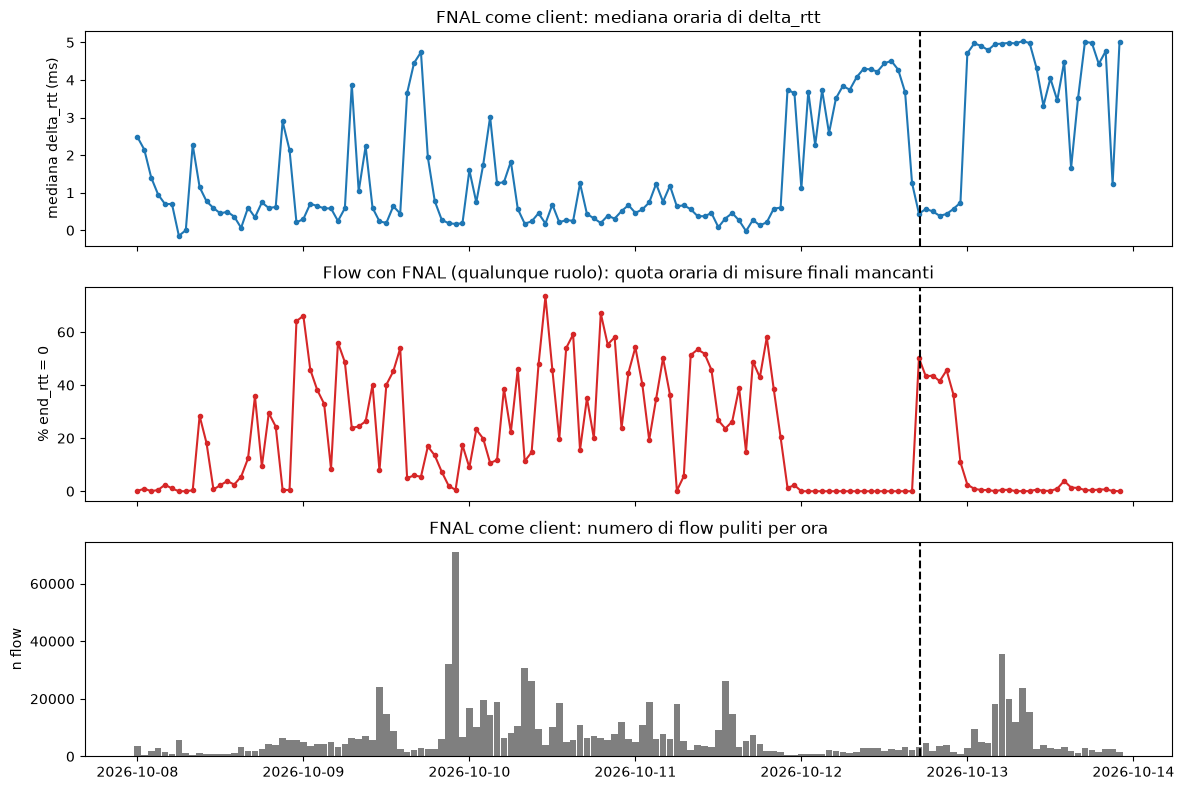

In [53]:
import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

ax1.plot(orario["ora"], orario["mediana_delta"], marker=".")
ax1.set_ylabel("mediana delta_rtt (ms)")
ax1.set_title("FNAL come client: mediana oraria di delta_rtt")

ax2.plot(orario["ora"], orario["pct_end_zero"], marker=".", color="tab:red")
ax2.set_ylabel("% end_rtt = 0")
ax2.set_title("Flow con FNAL (qualunque ruolo): quota oraria di misure finali mancanti")

ax3.bar(orario["ora"], orario["n_client"], width=0.04, color="tab:gray")
ax3.set_ylabel("n flow")
ax3.set_title("FNAL come client: numero di flow puliti per ora")

for ax in (ax1, ax2, ax3):
    ax.axvline(pd.Timestamp(TRAIN_END), linestyle="--", color="black")

plt.tight_layout()
plt.show()

### F2 – I flow sopravvissuti nelle ore di guasto

Classifichiamo ogni ora come *guasto attivo* (≥ 10 % di `end_rtt = 0` tra i flow FNAL) o *guasto spento*,
e confrontiamo i flow puliti con FNAL come client nei due stati: mediana di `delta_rtt`, quota di
`delta_rtt` **esattamente** 0 (misura finale identica a quella iniziale), quota quasi nulla (|·| < 0,05 ms)
e quota di flow lunghi.

- Molti zeri esatti solo a guasto attivo → probabile **artefatto di misura**: la misura finale viene
  ricopiata da quella iniziale, e quei `delta_rtt` non sono affidabili.
- Valori piccoli ma non esattamente nulli → più probabile un **effetto reale** del tipo di traffico.

La soglia del 10 % è una scelta di comodo; i risultati vanno controllati anche con soglie diverse.

In [54]:
SOGLIA_GUASTO = 10   # % di end_rtt = 0 oltre cui l'ora è "guasto attivo"

con.register("orario_df", orario[["ora", "pct_end_zero"]])

f2 = con.execute(f"""
    SELECT CASE WHEN o.pct_end_zero >= {SOGLIA_GUASTO}
                THEN 'guasto attivo' ELSE 'guasto spento' END                 AS stato,
           f.split,
           COUNT(*)                                                          AS n,
           MEDIAN(f.delta_rtt)                                               AS mediana,
           100 * AVG(CASE WHEN f.delta_rtt = 0 THEN 1 ELSE 0 END)            AS pct_zero_esatto,
           100 * AVG(CASE WHEN ABS(f.delta_rtt) < 0.05 THEN 1 ELSE 0 END)    AS pct_quasi_zero,
           100 * AVG(CASE WHEN f.an_durata_s > 60 THEN 1 ELSE 0 END)         AS pct_lunghi
    FROM fp AS f
    JOIN orario_df AS o
      ON date_trunc('hour', f.t_start) = o.ora
    WHERE f.split IN ('train', 'val')
      AND f.client_site = 'USCMS-FNAL-WC1'
    GROUP BY stato, f.split
    ORDER BY f.split DESC, stato
""").df()

f2.round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,stato,split,n,mediana,pct_zero_esatto,pct_quasi_zero,pct_lunghi
0,guasto attivo,val,19374,0.465,0.501,4.274,19.376
1,guasto spento,val,178655,4.963,0.216,1.281,79.478
2,guasto attivo,train,511411,0.425,0.556,9.021,50.554
3,guasto spento,train,258238,0.311,0.365,12.813,31.756


### F2 – Risultati e conclusione dell'indagine FNAL

| Split | Stato | n | Mediana | % zero esatto | % \|δ\| < 0,05 | % lunghi |
|---|---|---|---|---|---|---|
| train | guasto attivo | 511.411 | 0,425 | 0,556 | 9,021 | 50,6 |
| train | guasto spento | 258.238 | 0,311 | 0,365 | 12,813 | 31,8 |
| val | guasto attivo | 19.374 | 0,465 | 0,501 | 4,274 | 19,4 |
| val | guasto spento | 178.655 | 4,963 | 0,216 | 1,281 | 79,5 |

- **Nessuna misura ricopiata:** gli zeri esatti sono rari (0,2–0,6 %) e non aumentano a guasto attivo.
  L'ipotesi di un `end_rtt` falso ma non nullo non è supportata.
- **Nel train FNAL client ha `delta_rtt` ≈ 0 anche a guasto spento** (mediana 0,31 ms), e anche quando
  metà dei flow è lunga (0,43 ms con il 51 % di flow lunghi): non è un effetto della composizione del traffico.
- **Lettura complessiva (con il grafico F1):** FNAL attraversa due regimi nel tempo, uno con
  `delta_rtt` ≈ 0 (8–11 ottobre e sera del 12) e uno con ~5 ms come gli altri siti (12 ottobre di giorno,
  13 ottobre). I passaggi coincidono con l'inizio e la fine degli episodi di guasto della telemetria:
  il guasto sembra un sintomo dello stesso stato, non la causa dei valori bassi.

**Decisione.** I dati restano invariati (nessuna prova che il target del train sia errato).
Il cambio di regime non è prevedibile da input disponibili all'inizio del flow (il tempo assoluto non
generalizza con uno split cronologico; la quota di guasti dell'ora usa informazione di fine flow):
su FNAL ci aspettiamo un errore irriducibile dovuto a drift, riportato come sottogruppo per tutti i modelli.
Causa da chiarire con CERN IT.

### Decisione su FNAL --> finale !!!

**I dati restano invariati**: nessun flow FNAL viene rimosso o corretto.

**Perché.**
- **Nessuna prova che il target del train sia errato.** L'ipotesi di misure finali "ricopiate"
  durante i guasti di telemetria non è supportata (F2): gli zeri esatti sono rari e non aumentano
  a guasto attivo. I valori bassi di FNAL nel train sembrano un comportamento reale di quel periodo.
- **Rimuovere dati senza prove sarebbe arbitrario** e potrebbe introdurre un bias di selezione.
- **Impatto limitato:** FNAL è ~2 % della validation (215.471 flow su 10.069.254).

**Conseguenze.**
- Tutti i modelli (baseline e tokenizzazione) usano gli stessi dati.
- FNAL resta un sottogruppo della valutazione, riportato per ogni modello.
- Su FNAL ci aspettiamo un errore irriducibile dovuto a un **drift** tra train e validation:
  il cambio di regime avviene nel tempo e nessun input disponibile all'inizio del flow lo segnala.
- Domanda aperta per CERN IT. Se i dati di quei periodi risultassero inaffidabili, verranno
  esclusi e tutti i modelli rieseguiti.